<center><h1>Chen_Sian_HW4</h1></center>
<br>
<br>

Name: Sian Chen
<br>
Github Username: Ryan6546ea
<br>
USC ID: 3132413754

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
from pathlib import Path
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from scipy.stats import norm
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import cross_val_score

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


Get the AReM Data Set

In [2]:
files = sorted(Path("../data/AReM").glob("*/*.csv"))

### (b) Splitting Data

In [3]:
test_files = [
    f for f in files
    if int(f.stem[7:]) <= (2 if f.parent.name.startswith("bending") else 3)
]

train_files = [f for f in files if f not in test_files]

### (c) Feature Extraction

In [4]:
features = []

for f in files:
    data = pd.read_csv(
        f, comment="#", header=None, sep=r"[,\s]+",
        engine="python", usecols=range(1, 7)
    )
    features.append(data.describe().loc[
        ["min", "max", "mean", "50%", "std", "25%", "75%"]
    ].T.to_numpy().ravel())

features = pd.DataFrame(
    features,
    columns=[
        f"{s}_{i}"
        for i in range(1, 7)
        for s in ["min", "max", "mean", "median", "std", "q1", "q3"]
    ],
    index=files
)
features.index.name = "File"

features

,min_1,max_1,mean_1,median_1,std_1,q1_1,q3_1,min_2,max_2,mean_2,...,std_5,q1_5,q3_5,min_6,max_6,mean_6,median_6,std_6,q1_6,q3_6
File,,,,,,,,,,,,,,,,,,,,,
..\data\AReM\bending1\dataset1.csv,37.25,45.00,40.624792,40.500,1.476967,39.25,42.0000,0.0,1.30,0.358604,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.430,0.582915,0.00,1.3000
..\data\AReM\bending1\dataset2.csv,38.00,45.67,42.812812,42.500,1.435550,42.00,43.6700,0.0,1.22,0.372437,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.430,0.601010,0.00,1.3000
..\data\AReM\bending1\dataset3.csv,35.00,47.40,43.954500,44.330,1.558835,43.00,45.0000,0.0,1.70,0.426250,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.430,0.513506,0.00,0.9400
..\data\AReM\bending1\dataset4.csv,33.00,47.75,42.179812,43.500,3.670666,39.15,45.0000,0.0,3.00,0.696042,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.500,0.524317,0.00,1.0000
..\data\AReM\bending1\dataset5.csv,33.00,45.75,41.678063,41.750,2.243490,41.33,42.7500,0.0,2.83,0.535979,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.430,0.389164,0.00,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
..\data\AReM\walking\dataset5.csv,20.75,46.25,34.763333,35.290,4.742208,31.67,38.2500,0.0,12.68,4.223792,...,3.174681,14.2500,18.33,0.0,9.39,3.288271,3.270,1.647528,2.05,4.3050
..\data\AReM\walking\dataset6.csv,21.50,51.00,34.935812,35.500,4.645944,32.00,38.0625,0.0,12.21,4.115750,...,3.192058,14.2375,18.25,0.0,10.21,3.280021,3.015,1.700918,2.12,4.5000
..\data\AReM\walking\dataset7.csv,18.33,47.67,34.333042,34.750,4.948770,31.25,38.0000,0.0,12.48,4.396958,...,3.000493,13.7500,18.00,0.0,8.01,3.261583,2.980,1.617290,2.05,4.3200


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

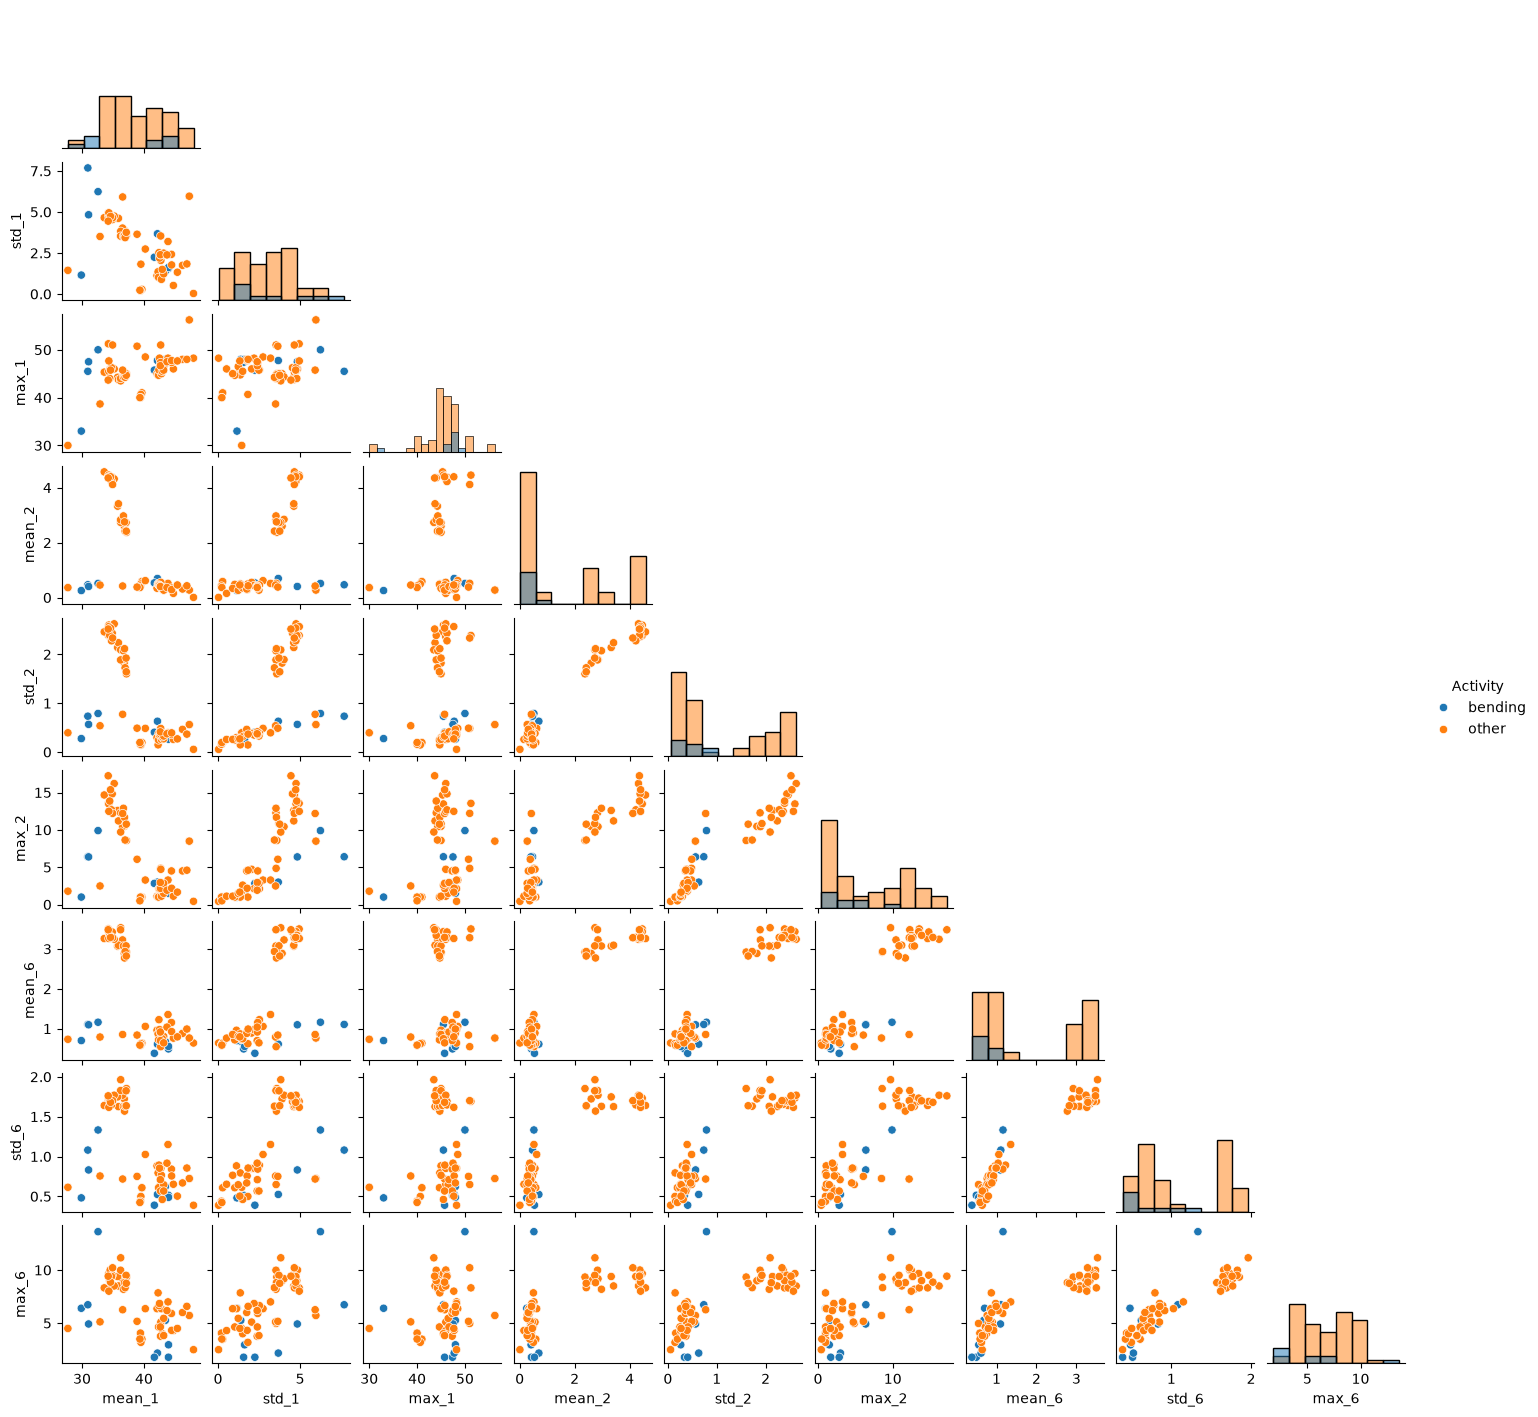

In [5]:
cols = [
    f"{s}_{i}"
    for i in [1, 2, 6]
    for s in ["mean", "std", "max"]
]

plot_data = features.loc[train_files, cols].copy()
plot_data["Activity"] = [
    "bending" if f.parent.name.startswith("bending") else "other"
    for f in plot_data.index
]

sns.pairplot(
    plot_data, hue="Activity",
    diag_kind="hist", corner=True, height=1.6
)
plt.show()

#### ii. Splitted Plots

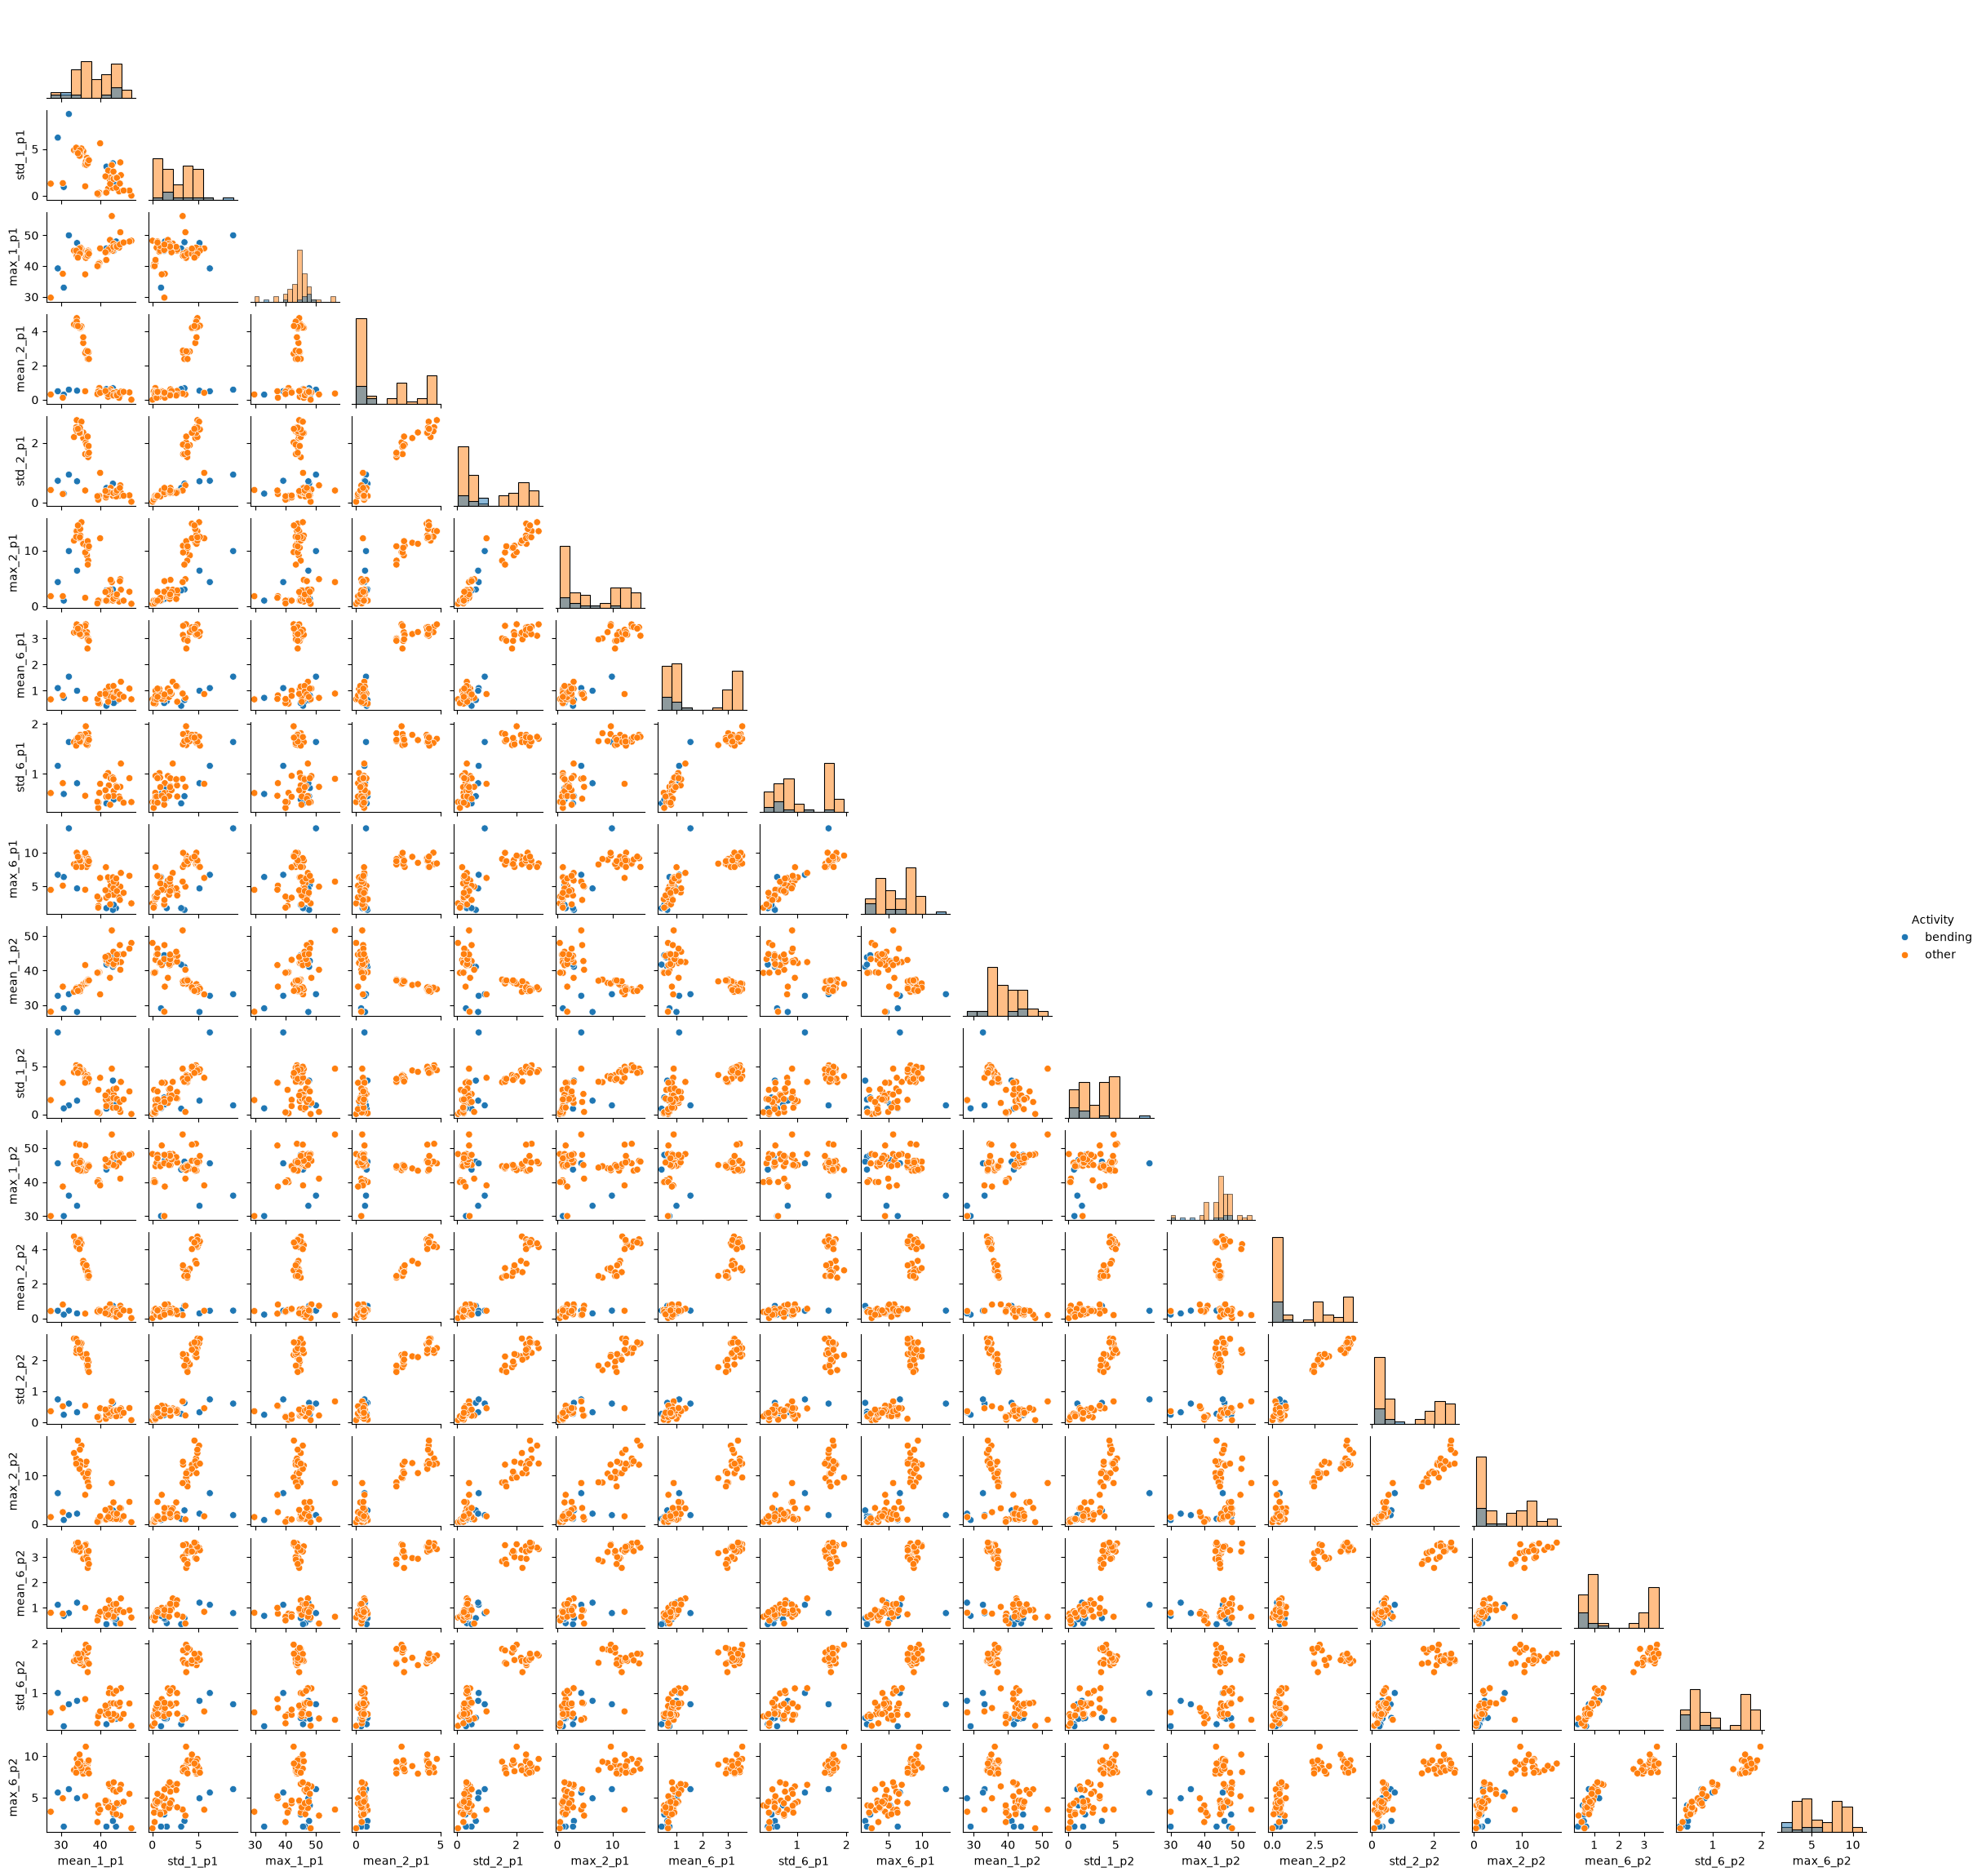

In [6]:
rows = []

for f in train_files:
    data = pd.read_csv(
        f, comment="#", header=None, sep=r"[,\s]+",
        engine="python", usecols=range(1, 7)
    )
    mid = len(data) // 2
    row = []
    for part in [data.iloc[:mid], data.iloc[mid:]]:
        row.extend(
            part[[1, 2, 6]].agg(["mean", "std", "max"]).T.to_numpy().ravel()
        )
    rows.append(row)

cols2 = [
    f"{s}_{i}_p{j}"
    for j in [1, 2]
    for i in [1, 2, 6]
    for s in ["mean", "std", "max"]
]

plot_data2 = pd.DataFrame(rows, columns=cols2, index=train_files)
plot_data2["Activity"] = plot_data["Activity"]

sns.pairplot(
    plot_data2, hue="Activity",
    diag_kind="hist", corner=True, height=1.3
)
plt.show()

The overall class separation is similar to that in 2(a)(i).
Splitting the time series reveals some differences between the two halves,
but bending and other activities still overlap in many feature pairs.
The plots do not show a considerable overall improvement in class separation.

#### iii. Time Series Segments

In [7]:
train_series = [
    pd.read_csv(
        f, comment="#", header=None, sep=r"[,\s]+",
        engine="python", usecols=range(1, 7)
    )
    for f in train_files
]
y_train = np.array([int(f.parent.name.startswith("bending")) for f in train_files])

def segment_features(series, l):
    rows = []
    for data in series:
        row = []
        for idx in np.array_split(np.arange(len(data)), l):
            row.extend(data.iloc[idx].describe().loc[
                ["min", "max", "mean", "50%", "std", "25%", "75%"]
            ].T.to_numpy().ravel())
        rows.append(row)
    return pd.DataFrame(rows, columns=[
        f"{s}_{i}_p{j}"
        for j in range(1, l + 1)
        for i in range(1, 7)
        for s in ["min", "max", "mean", "median", "std", "q1", "q3"]
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1e6, solver="liblinear", max_iter=2000, random_state=42)
)

results = []
best_score = -1

for l in range(1, 21):
    X = segment_features(train_series, l)
    selector = RFECV(
        model, step=1, cv=cv, scoring="accuracy",
        importance_getter="named_steps.logisticregression.coef_"
    ).fit(X, y_train)
    score = selector.cv_results_["mean_test_score"].max()
    results.append([l, selector.n_features_, score])
    if score > best_score:
        best_l, best_score = l, score
        best_model, best_X = selector, X

results = pd.DataFrame(results, columns=["l", "p", "CV accuracy"])
display(results)
print(f"Best: l={best_l}, p={best_model.n_features_}, CV accuracy={best_score:.4f}")
print("Selected features:", best_X.columns[best_model.support_].tolist())

,l,p,CV accuracy
0,1,3,1.000000
1,2,10,0.942857
2,3,7,0.942857
3,4,13,0.971429
4,5,5,0.942857
5,6,6,0.971429
6,7,8,0.957143
7,8,10,0.957143
8,9,8,0.957143
9,10,5,0.985714


Best: l=1, p=3, CV accuracy=1.0000
Selected features: ['min_5_p1', 'max_5_p1', 'mean_5_p1']


I used RFE with stratified 5-fold cross-validation to select the best
(l, p) based on mean validation accuracy. Each instance has 42l candidate
features, while the number of training instances remains 69.

The correct approach is to fit standardization, perform feature selection,
and train the classifier using only the training portion of each fold,
then evaluate on its validation portion. Extracting fixed statistics
independently from each instance before cross-validation is valid.

The wrong approach is to standardize or select features using the entire
training set before cross-validation, which leaks validation information.
The held-out test set must not be used for model selection.

Stratified cross-validation approximately preserves class proportions.
With 9 bending and 60 other instances, it ensures that every validation
fold contains both classes.

#### iv. Confusion Matrix

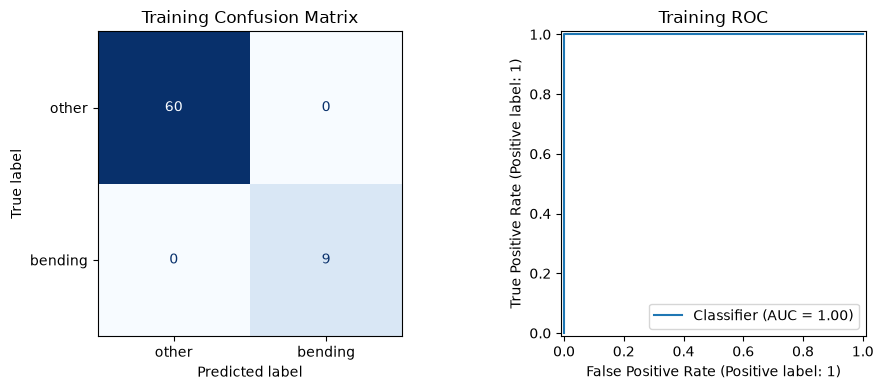

,Coefficient,Approx. Wald p-value
Intercept,-77.413098,0.708117
min_5_p1,92.414322,0.657208
max_5_p1,70.146644,0.655649
mean_5_p1,-49.026065,0.841133


In [8]:
pred_train = best_model.predict(best_X)
prob_train = best_model.predict_proba(best_X)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(
    y_train, pred_train, labels=[0, 1], display_labels=["other", "bending"],
    cmap="Blues", colorbar=False, ax=axes[0]
)
RocCurveDisplay.from_predictions(y_train, prob_train, pos_label=1, ax=axes[1])
axes[0].set_title("Training Confusion Matrix")
axes[1].set_title("Training ROC")
plt.tight_layout()
plt.show()

pipe = best_model.estimator_
Z = pipe.named_steps["standardscaler"].transform(best_model.transform(best_X))
Z = np.column_stack([np.ones(len(Z)), Z])
lr = pipe.named_steps["logisticregression"]
beta = np.r_[lr.intercept_, lr.coef_.ravel()]

w = prob_train * (1 - prob_train)
se = np.sqrt(np.diag(np.linalg.inv(Z.T @ (w[:, None] * Z))))
params = pd.DataFrame(
    {"Coefficient": beta, "Approx. Wald p-value": 2 * norm.sf(np.abs(beta / se))},
    index=["Intercept"] + best_X.columns[best_model.support_].tolist()
)
display(params)

The training confusion matrix is [[60, 0], [0, 9]], with other as class 0
and bending as class 1. All training instances are classified correctly,
and the training AUC is 1.000.

The reported coefficients correspond to the standardized selected features.
The numerical Wald values are calculated from the observed information
at the fitted finite coefficients.

The training data exhibit complete separation, so the unpenalized logistic
regression MLE is not finite. Therefore, these numerical Wald values are
not reliable inferential p-values. Their large values should not be
interpreted as evidence that the selected features are unimportant.

#### v. Test Classifier

In [9]:
test_series = [
    pd.read_csv(
        f, comment="#", header=None, sep=r"[,\s]+",
        engine="python", usecols=range(1, 7)
    )
    for f in test_files
]

X_test = segment_features(test_series, best_l)
y_test = np.array([int(f.parent.name.startswith("bending")) for f in test_files])
pred_test = best_model.predict(X_test)
test_accuracy = np.mean(pred_test == y_test)

print(f"CV accuracy: {best_score:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

CV accuracy: 1.0000
Test accuracy: 0.9474


I used the selected l = 1 and applied the same feature extraction,
selected features, and training-fitted standardization to the test set.

The test accuracy is 18/19 = 94.74%, compared with the 5-fold
cross-validation accuracy of 100%. The test accuracy is therefore
about 5.26 percentage points lower than the cross-validation accuracy.

#### vi. Separation

Yes. The selected features completely separate the training classes.
The training confusion matrix is [[60, 0], [0, 9]], and the training
AUC is 1.000. The standardized feature coefficients are also large:
approximately 92.41, 70.15, and -49.03.

Under complete separation, unpenalized logistic regression has no finite
maximum likelihood estimate: some coefficient magnitudes can increase
without bound as the likelihood improves. This causes problems in
parameter estimation and makes conventional Wald p-values unreliable.

Here, C = 1e6 retains a very weak L2 penalty, which produces finite
fitted coefficients. However, the numerical Wald approximations reported
above should not be interpreted as reliable significance tests.

#### vii. Imbalance

Intercept adjustment: -1.8971


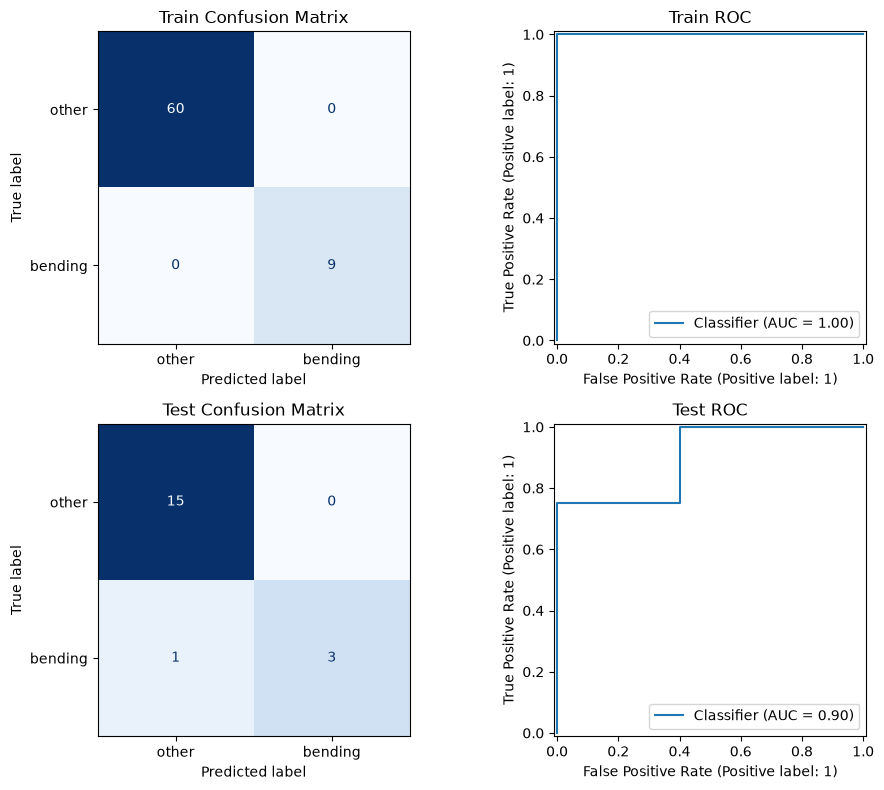

In [10]:
cases = np.flatnonzero(y_train == 1)
controls = np.flatnonzero(y_train == 0)
rng = np.random.default_rng(42)
sample_idx = np.r_[cases, rng.choice(controls, len(cases), replace=False)]

X_train_cc = best_model.transform(best_X)
X_test_cc = best_model.transform(X_test)
cc_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1e6, solver="liblinear", max_iter=2000, random_state=42)
)
cc_model.fit(X_train_cc[sample_idx], y_train[sample_idx])

pi = y_train.mean()
pi_sample = y_train[sample_idx].mean()
shift = np.log(pi / (1 - pi)) - np.log(pi_sample / (1 - pi_sample))
cc_model.named_steps["logisticregression"].intercept_ += shift
print(f"Intercept adjustment: {shift:.4f}")

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for row, (name, X, y) in enumerate([
    ("Train", X_train_cc, y_train),
    ("Test", X_test_cc, y_test)
]):
    pred = cc_model.predict(X)
    prob = cc_model.predict_proba(X)[:, 1]
    ConfusionMatrixDisplay.from_predictions(
        y, pred, labels=[0, 1], display_labels=["other", "bending"],
        cmap="Blues", colorbar=False, ax=axes[row, 0]
    )
    RocCurveDisplay.from_predictions(y, prob, pos_label=1, ax=axes[row, 1])
    axes[row, 0].set_title(f"{name} Confusion Matrix")
    axes[row, 1].set_title(f"{name} ROC")

plt.tight_layout()
plt.show()

Yes. The original training set is imbalanced, with 9 bending instances
and 60 other instances.

I retained all 9 bending cases and randomly sampled 9 other controls
without replacement. I fitted logistic regression using the previously
selected three features.

Using the original training case fraction as an estimate of the target
prior, I adjusted the intercept by
logit(9/69) - logit(1/2) = -1.8971.

I evaluated the adjusted model on the original training and test sets.
The training confusion matrix is [[60, 0], [0, 9]], with AUC = 1.000.
The test confusion matrix is [[15, 0], [1, 3]], with AUC = 0.900.
The test accuracy remains 18/19 = 94.74%, so this sampling run does not
improve test accuracy over the original model.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [11]:
l1_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(l1_ratio=1, solver="liblinear", max_iter=2000, random_state=42)
)
l1_results = []
best_l1_score = -1

for l in range(1, 21):
    X = segment_features(train_series, l)
    search = GridSearchCV(
        l1_model, {"logisticregression__C": np.logspace(-4, 4, 9)},
        cv=cv, scoring="accuracy"
    ).fit(X, y_train)
    C = search.best_params_["logisticregression__C"]
    score = search.best_score_
    l1_results.append([l, C, score])
    if score > best_l1_score:
        best_l1_l, best_l1_C, best_l1_score = l, C, score
        best_l1_model, best_l1_X = search.best_estimator_, X

l1_results = pd.DataFrame(l1_results, columns=["l", "C", "CV accuracy"])
display(l1_results)

selected_l1 = best_l1_X.columns[
    best_l1_model.named_steps["logisticregression"].coef_[0] != 0
]
print(f"Best: l={best_l1_l}, C={best_l1_C:g}, CV accuracy={best_l1_score:.4f}")
print(f"Selected features ({len(selected_l1)}):", selected_l1.tolist())

,l,C,CV accuracy
0,1,10000.0,0.985714
1,2,10.0,0.971429
2,3,1.0,0.957143
3,4,1000.0,0.957143
4,5,100.0,0.941758
5,6,10.0,0.957143
6,7,100.0,0.956044
7,8,100.0,0.942857
8,9,10000.0,0.942857
9,10,100.0,0.971429


Best: l=1, C=10000, CV accuracy=0.9857
Selected features (36): ['min_1_p1', 'max_1_p1', 'mean_1_p1', 'median_1_p1', 'std_1_p1', 'q1_1_p1', 'q3_1_p1', 'max_2_p1', 'mean_2_p1', 'median_2_p1', 'std_2_p1', 'q3_2_p1', 'min_3_p1', 'max_3_p1', 'median_3_p1', 'std_3_p1', 'q1_3_p1', 'q3_3_p1', 'max_4_p1', 'mean_4_p1', 'median_4_p1', 'std_4_p1', 'q1_4_p1', 'min_5_p1', 'max_5_p1', 'mean_5_p1', 'median_5_p1', 'std_5_p1', 'q1_5_p1', 'min_6_p1', 'max_6_p1', 'mean_6_p1', 'median_6_p1', 'std_6_p1', 'q1_6_p1', 'q3_6_p1']


I used stratified 5-fold cross-validation to select both the number of
segments l and the regularization parameter C, searching l = 1, ..., 20
and nine logarithmically spaced C values from 0.0001 to 10000.

The best pair in this grid is l = 1 and C = 10000, with a mean
cross-validation accuracy of 98.57%. After refitting on the full
training set, 36 of the 42 features have nonzero coefficients.

The correct approach fits the scaler and the L1 logistic regression
model within each training fold and evaluates them on the validation
fold. Standardizing or selecting features using the entire training
set before cross-validation would leak validation information.
Stratification approximately preserves the class proportions in each
fold. The test set is not used for parameter selection.

#### ii. Comparison

In part (a), I used RFE, the permitted alternative to p-value-based
variable selection.

The RFE model achieved a CV accuracy of 100%, compared with 98.57%
for L1 logistic regression. It retained 3 features, while L1 retained
36. Thus, RFE performed better in this cross-validation comparison
and used fewer features.

L1 regularization is easier to implement than p-value-based selection
because it performs feature selection during model fitting, avoiding
separate p-value calculations and feature-pruning steps.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

c:\Users\a2785\Desktop\552\Homework\HW4\HW4\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


,l,C,CV accuracy
0,1,1.0,0.884615
1,2,100.0,0.928571
2,3,1.0,0.827473
3,4,100.0,0.856044
4,5,100.0,0.870330
5,6,10.0,0.841758
6,7,100.0,0.827473
7,8,100.0,0.856044
8,9,100.0,0.841758
9,10,10.0,0.812088


Best: l=2, C=100, CV accuracy=0.9286
Test error: 0.1579


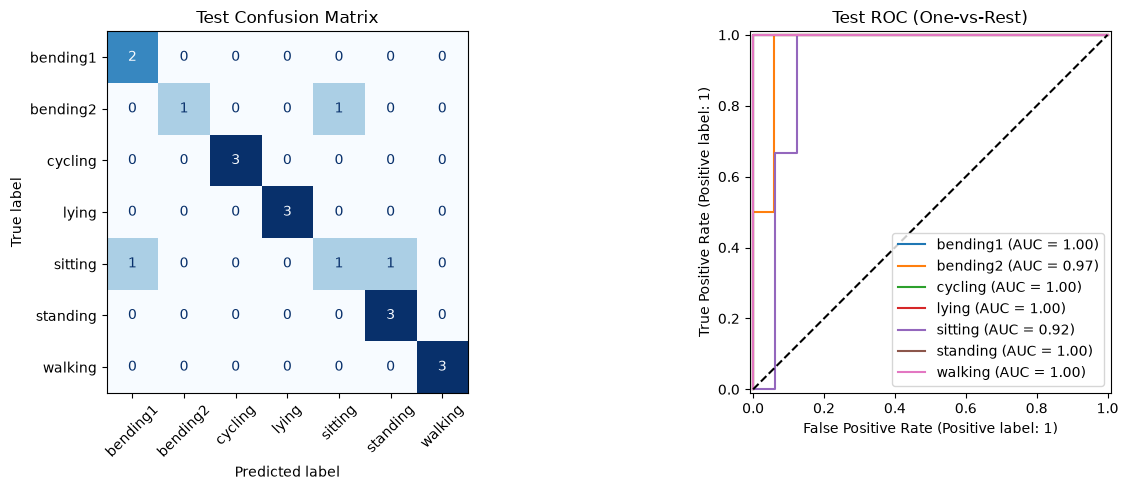

In [12]:
y_train_multi = np.array([f.parent.name for f in train_files])
y_test_multi = np.array([f.parent.name for f in test_files])
cv_multi = list(cv.split(train_series, y_train_multi))

multi_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        l1_ratio=1, solver="saga", max_iter=5000, tol=1e-3, random_state=42
    )
)
multi_results = []
best_multi_score = -1

for l in range(1, 21):
    X = segment_features(train_series, l)
    search = GridSearchCV(
        multi_model, {"logisticregression__C": np.logspace(-4, 4, 9)},
        cv=cv_multi, scoring="accuracy", n_jobs=4
    ).fit(X, y_train_multi)
    C = search.best_params_["logisticregression__C"]
    score = search.best_score_
    multi_results.append([l, C, score])
    if score > best_multi_score:
        best_multi_l, best_multi_C, best_multi_score = l, C, score
        best_multi_model = search.best_estimator_

multi_results = pd.DataFrame(multi_results, columns=["l", "C", "CV accuracy"])
display(multi_results)
print(f"Best: l={best_multi_l}, C={best_multi_C:g}, CV accuracy={best_multi_score:.4f}")

X_test_multi = segment_features(test_series, best_multi_l)
pred_multi = best_multi_model.predict(X_test_multi)
prob_multi = best_multi_model.predict_proba(X_test_multi)
multi_test_error = np.mean(pred_multi != y_test_multi)
print(f"Test error: {multi_test_error:.4f}")

classes = best_multi_model.classes_
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_multi, pred_multi, labels=classes,
    cmap="Blues", colorbar=False, xticks_rotation=45, ax=axes[0]
)
axes[0].set_title("Test Confusion Matrix")

for i, label in enumerate(classes):
    RocCurveDisplay.from_predictions(
        y_test_multi == label, prob_multi[:, i], name=label, ax=axes[1]
    )
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("Test ROC (One-vs-Rest)")
plt.tight_layout()
plt.show()

I used L1-penalized multinomial logistic regression to classify all
seven activities. Stratified 5-fold cross-validation selected l and C
using the same search grid as in part (b), with standardization fitted
within each training fold.

The best pair in this grid is l = 2 and C = 100, with a mean CV
accuracy of 92.86%. The test error is 3/19 = 15.79%.

The 7 × 7 confusion matrix has true classes in rows and predicted
classes in columns. Diagonal entries represent correct predictions.

For ROC evaluation, I used one-vs-rest: each activity is treated as
the positive class and all remaining activities as the negative class.
Each curve plots the true positive rate against the false positive
rate as the threshold on that class's predicted probability varies.
The legend reports the AUC for each class.

The bending2 class has only four training instances, so one validation
fold lacks this class. Every training fold still contains all seven
classes, and validation accuracy remains defined.

#### ii. Naive Bayes

Model,Gaussian NB,Multinomial NB
l,,
1,0.857143,0.854945
2,0.827473,0.795604
3,0.681319,0.796703
4,0.725275,0.782418
5,0.652747,0.812088
6,0.652747,0.783516
7,0.695604,0.783516
8,0.667033,0.782418
9,0.638462,0.783516


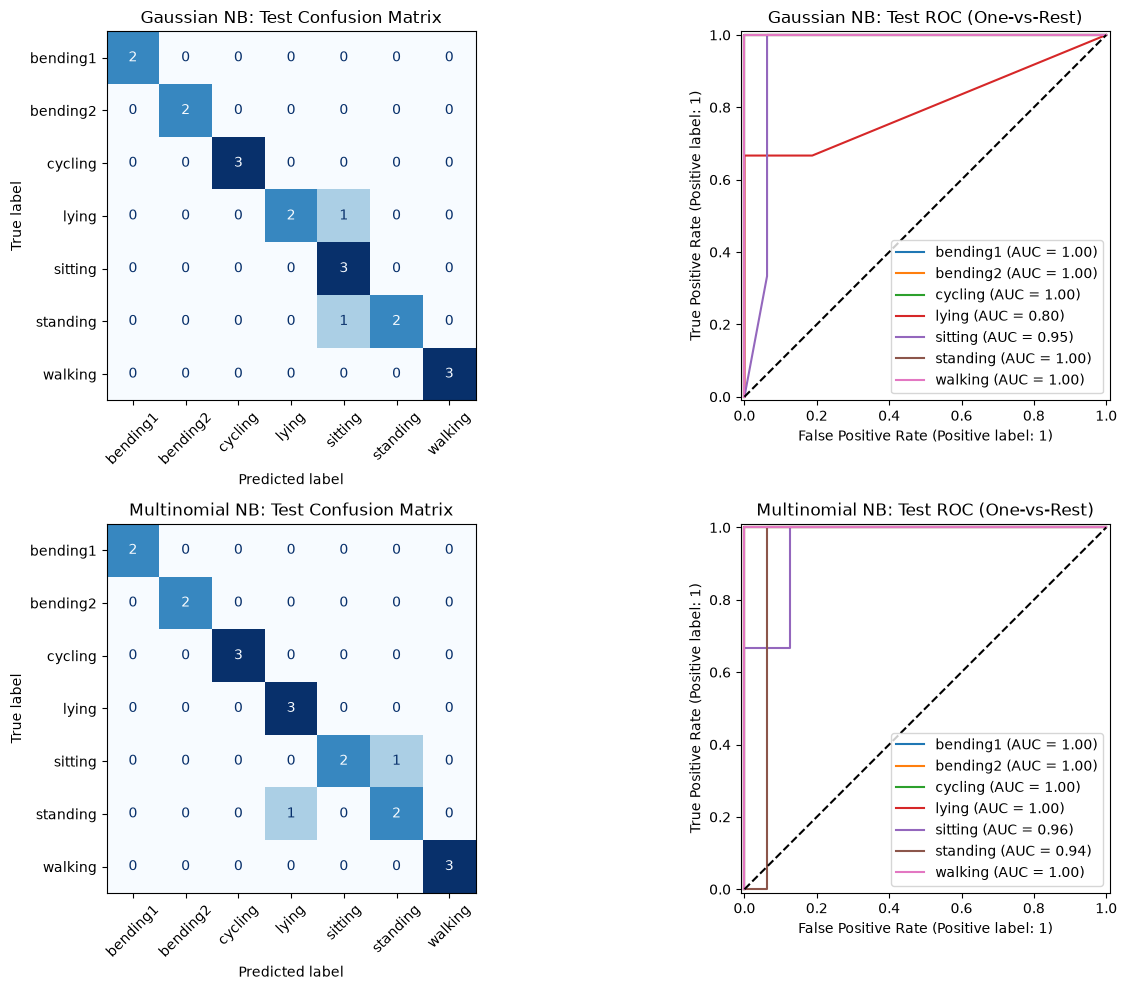

,Model,Best l,CV accuracy,Test error
0,Gaussian NB,1,0.857143,0.105263
1,Multinomial NB,1,0.854945,0.105263


In [13]:
nb_models = {"Gaussian NB": GaussianNB, "Multinomial NB": MultinomialNB}
nb_best = {}
nb_results = []

for l in range(1, 21):
    X = segment_features(train_series, l)
    for name, NB in nb_models.items():
        score = cross_val_score(
            NB(), X, y_train_multi, cv=cv_multi, scoring="accuracy"
        ).mean()
        nb_results.append([name, l, score])
        if name not in nb_best or score > nb_best[name]["score"]:
            nb_best[name] = {
                "l": l, "score": score, "model": NB().fit(X, y_train_multi)
            }

nb_results = pd.DataFrame(nb_results, columns=["Model", "l", "CV accuracy"])
display(nb_results.pivot(index="l", columns="Model", values="CV accuracy"))

nb_comparison = []
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for row, (name, best) in enumerate(nb_best.items()):
    model = best["model"]
    X_test_nb = segment_features(test_series, best["l"])
    pred = model.predict(X_test_nb)
    prob = model.predict_proba(X_test_nb)
    error = np.mean(pred != y_test_multi)
    nb_comparison.append([name, best["l"], best["score"], error])

    ConfusionMatrixDisplay.from_predictions(
        y_test_multi, pred, labels=model.classes_, cmap="Blues",
        colorbar=False, xticks_rotation=45, ax=axes[row, 0]
    )
    axes[row, 0].set_title(f"{name}: Test Confusion Matrix")

    for i, label in enumerate(model.classes_):
        RocCurveDisplay.from_predictions(
            y_test_multi == label, prob[:, i], name=label, ax=axes[row, 1]
        )
    axes[row, 1].plot([0, 1], [0, 1], "k--")
    axes[row, 1].set_title(f"{name}: Test ROC (One-vs-Rest)")

plt.tight_layout()
plt.show()

nb_comparison = pd.DataFrame(
    nb_comparison, columns=["Model", "Best l", "CV accuracy", "Test error"]
)
display(nb_comparison)

I selected l separately for Gaussian NB and Multinomial NB using the
same stratified 5-fold splits as in part (c)(i). Other model parameters
were kept at their defaults. I used the original nonnegative features
without standardization.

Both models selected l = 1. Gaussian NB achieved a CV accuracy of
85.71%, while Multinomial NB achieved 85.49%. Both models misclassified
2 of the 19 test instances, giving a test error of 10.53%.

Gaussian NB has slightly higher CV accuracy, but neither model has
lower test error in this experiment. Their confusion matrices show
different misclassifications, and the one-vs-rest ROC curves report
the AUC for each class.

Gaussian NB assumes Gaussian class-conditional feature distributions.
Multinomial NB normally models counts; using these continuous,
nonnegative statistics is an approximation.

#### iii. Comparison

Gaussian NB and Multinomial NB both achieved a test error of 10.53%
(2/19), compared with 15.79% (3/19) for L1 multinomial logistic
regression. Therefore, the two Naive Bayes models tie for the best
test performance in this experiment.

However, L1 multinomial logistic regression achieved the highest CV
accuracy of 92.86%, compared with 85.71% for Gaussian NB and 85.49%
for Multinomial NB.

The test difference is only one instance out of 19, so these results
do not establish that Naive Bayes is generally superior.

## 3. ISLR 4.8.3

Let $\pi_k=P(Y=k)$. By Bayes' theorem, the classifier assigns $x$
to the class maximizing $\pi_k f_k(x)$, where

$$
f_k(x)=\frac{1}{\sqrt{2\pi\sigma_k^2}}
\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).
$$

Taking logarithms and dropping terms common to all classes gives
the discriminant function

$$
\begin{aligned}
\delta_k(x)
&=\log\pi_k-\frac12\log\sigma_k^2
-\frac{(x-\mu_k)^2}{2\sigma_k^2}\\
&=-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\frac12\log\sigma_k^2+\log\pi_k.
\end{aligned}
$$

The decision boundary between classes $k$ and $j$ satisfies
$\delta_k(x)-\delta_j(x)=0$. Its coefficient of $x^2$ is

$$
\frac{1}{2\sigma_j^2}-\frac{1}{2\sigma_k^2},
$$

which is nonzero when the two variances differ. Therefore, the
boundary equation is generally quadratic in $x$, giving QDA.

If all class variances are equal, the quadratic terms cancel when
comparing classes, and the rule reduces to the linear LDA rule.

## 4. ISLR 4.8.7

Let $Y=\text{Yes}$ denote issuing a dividend. The class priors are
$P(Y=\text{Yes})=0.8$ and $P(Y=\text{No})=0.2$, with

$$
X\mid Y=\text{Yes}\sim N(10,36),\qquad
X\mid Y=\text{No}\sim N(0,36).
$$

By Bayes' theorem,

$$
P(Y=\text{Yes}\mid X=4)
=\frac{0.8f_{\text{Yes}}(4)}
{0.8f_{\text{Yes}}(4)+0.2f_{\text{No}}(4)}.
$$

The normal densities have the same variance, so their common
normalizing constant cancels. Therefore,

$$
\begin{aligned}
P(Y=\text{Yes}\mid X=4)
&=\frac{0.8e^{-(4-10)^2/(2\cdot36)}}
{0.8e^{-(4-10)^2/(2\cdot36)}
+0.2e^{-(4-0)^2/(2\cdot36)}}\\
&=\frac{0.8e^{-1/2}}
{0.8e^{-1/2}+0.2e^{-2/9}}\\
&\approx 0.7519.
\end{aligned}
$$

Thus, the estimated probability that the company issues a dividend
is approximately **75.19%**.

## 5.1. Extra Practice ISLR 4.8.4

Under the uniform unit-hypercube model, ignoring boundary effects,
the expected fraction of observations in a region equals its volume.

**(a)** For $p=1$, the interval has length $0.1$, so we use
$0.1=10\%$ of the observations.

**(b)** For $p=2$, the region has area
$0.1\times0.1=0.01$, so we use $1\%$ of the observations.

**(c)** For $p=100$, the fraction is

$$
(0.1)^{100}=10^{-100},
$$

which is effectively zero for any practical sample size.

**(d)** The fraction of observations in a fixed local neighborhood
decreases exponentially with the number of dimensions. Consequently,
very few training observations are close to a test observation in
high dimensions, making local methods such as KNN less effective.

**(e)** Let $s$ be the side length of the hypercube. To contain an
expected fraction of $0.1$ of the observations, we need

$$
s^p=0.1
\quad\Longrightarrow\quad
s=0.1^{1/p}.
$$

For $p=1$, $s=0.1$.

For $p=2$, $s=\sqrt{0.1}\approx0.3162$.

For $p=100$, $s=0.1^{1/100}\approx0.9772$.

Thus, in 100 dimensions, each side must span approximately 97.72%
of the feature's range to include just 10% of the observations.
The neighborhood is therefore no longer very local.

## 5.2. Extra Practice ISLR 4.8.9

Let $p$ denote the probability of default. The odds of default are
$p/(1-p)$.

**(a)** Given odds of $0.37$,

$$
\frac{p}{1-p}=0.37
\quad\Longrightarrow\quad
p=\frac{0.37}{1+0.37}\approx0.2701.
$$

Therefore, approximately **27.01%** of these people will default.

**(b)** Given $p=0.16$,

$$
\text{odds}=\frac{0.16}{1-0.16}
=\frac{0.16}{0.84}
=\frac{4}{21}\approx0.1905.
$$

Thus, the odds of default are approximately **0.1905**, or **4:21**.